## Experiment 1 - Three-layer neural network from scratch (MNIST)

**Dataset: MNIST**  
Download link: https://www.kaggle.com/datasets/hojjatk/mnist-dataset (official: http://yann.lecun.com/exdb/mnist/)  
The code below downloads it automatically; use the link only if you want the raw files.

In [1]:
%pip install -q tensorflow tensorflow-datasets scikit-learn matplotlib pandas pillow kagglehub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


C:\Users\vishv\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


A local file was found, but it seems to be incomplete or outdated because the auto file hash does not match the original value of 731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1 so we will re-download the data.
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 30s 3us/step 
Epoch  1  loss=0.4211  test acc=0.9329
Epoch  2  loss=0.2018  test acc=0.9506
Epoch  3  loss=0.1517  test acc=0.9601
Epoch  4  loss=0.1219  test acc=0.9638
Epoch  5  loss=0.1026  test acc=0.9689
Epoch  6  loss=0.0887  test acc=0.9692
Epoch  7  loss=0.0766  test acc=0.9695
Epoch  8  loss=0.0675  test acc=0.9746
Epoch  9  loss=0.0594  test acc=0.9736
Epoch 10  loss=0.0536  test acc=0.9728


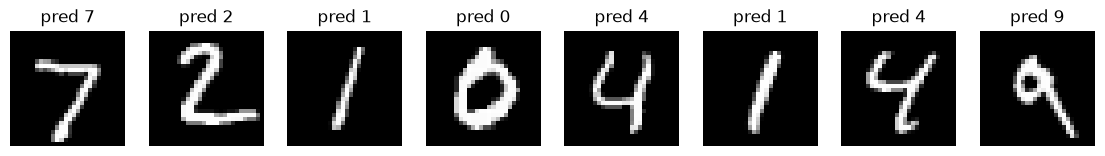

In [2]:
import numpy as np, matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

(xtr, ytr), (xte, yte) = mnist.load_data()
xtr = xtr.reshape(-1, 784) / 255.; xte = xte.reshape(-1, 784) / 255.
Y = np.eye(10)[ytr]

sizes = [784, 128, 64, 10]
rng = np.random.default_rng(0)
W = [rng.standard_normal((a, b)) * np.sqrt(2 / a) for a, b in zip(sizes[:-1], sizes[1:])]
B = [np.zeros(n) for n in sizes[1:]]

def softmax(z):
    e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def forward(x):
    a = [x]
    for i in range(3):
        z = a[-1] @ W[i] + B[i]
        a.append(np.maximum(z, 0) if i < 2 else softmax(z))   # ReLU, ReLU, Softmax
    return a

lr, bs = 0.1, 128
for ep in range(10):
    p = rng.permutation(len(xtr)); losses = []
    for s in range(0, len(xtr), bs):
        idx = p[s:s+bs]; x, y = xtr[idx], Y[idx]
        a = forward(x)
        losses.append(-np.mean(np.sum(y * np.log(a[3] + 1e-9), axis=1)))   # cross-entropy
        d = (a[3] - y)                                                      # softmax + CE gradient
        for i in (2, 1, 0):                                                 # backpropagation
            gW, gB = a[i].T @ d / len(x), d.mean(0)
            if i > 0: d_prev = (d @ W[i].T) * (a[i] > 0)
            W[i] -= lr * gW; B[i] -= lr * gB
            if i > 0: d = d_prev
    acc = (forward(xte)[3].argmax(1) == yte).mean()
    print(f"Epoch {ep+1:2d}  loss={np.mean(losses):.4f}  test acc={acc:.4f}")

pred = forward(xte[:8])[3].argmax(1)
fig, ax = plt.subplots(1, 8, figsize=(14, 2))
for i in range(8):
    ax[i].imshow(xte[i].reshape(28, 28), cmap='gray'); ax[i].set_title(f"pred {pred[i]}"); ax[i].axis('off')
plt.show()